# 01 · Análise Exploratória — o que os 10 primeiros minutos contam?

**Pergunta de negócio:** aos 10 minutos de partida, qual a probabilidade de o lado azul vencer?

Cada linha do dataset é um **snapshot aos 10 min** de uma partida ranqueada de elo alto
(9.879 partidas). Não há informação de pré-jogo (campeões, picks/bans, MMR) e nada de
pós-jogo entra como feature — o alvo `blue_wins` é a única informação do futuro.

**Objetivo deste notebook:** entender os dados e sair com uma lista de **decisões
justificadas** para a engenharia de features (Etapa 4). Os dados vêm da camada **bronze**,
que já passou pelo contrato Pandera (`lol_win.data.schemas.BRONZE_SCHEMA`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from lol_win.analysis.eda import (
    OUTCOME_PALETTE,
    TEAM_PALETTE,
    compute_vif,
    equality_rate,
    outlier_summary,
    save_figure,
    set_plot_style,
    target_correlations,
    win_rate_by_bins,
    win_rate_by_group,
)
from lol_win.config import BRONZE_PARQUET, TARGET
from lol_win.data.schemas import BRONZE_SCHEMA
from lol_win.features.build import side_diffs

set_plot_style()
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 50)

## 1. Estrutura e qualidade

Revalido o contrato na leitura: se o bronze estiver desatualizado ou corrompido, o notebook
falha aqui, não num gráfico lá na frente.

In [2]:
df = BRONZE_SCHEMA.validate(pd.read_parquet(BRONZE_PARQUET), lazy=True)
print(f"{df.shape[0]:,} partidas x {df.shape[1]} colunas")
print(f"Nulos: {df.isna().sum().sum()} · game_id duplicado: {df['game_id'].duplicated().sum()}")
df.dtypes.value_counts()

9,879 partidas x 40 colunas
Nulos: 0 · game_id duplicado: 0


int64      34
float64     6
Name: count, dtype: int64

In [3]:
df.head()

,game_id,blue_wins,blue_wards_placed,blue_wards_destroyed,blue_first_blood,blue_kills,blue_deaths,blue_assists,blue_elite_monsters,blue_dragons,blue_heralds,blue_towers_destroyed,blue_total_gold,blue_avg_level,blue_total_experience,blue_total_minions_killed,blue_total_jungle_minions_killed,blue_gold_diff,blue_experience_diff,blue_cs_per_min,blue_gold_per_min,red_wards_placed,red_wards_destroyed,red_first_blood,red_kills,red_deaths,red_assists,red_elite_monsters,red_dragons,red_heralds,red_towers_destroyed,red_total_gold,red_avg_level,red_total_experience,red_total_minions_killed,red_total_jungle_minions_killed,red_gold_diff,red_experience_diff,red_cs_per_min,red_gold_per_min
0,4519157822,0,28,2,1,9,6,11,0,0,0,0,17210,6.600,17039,195,36,643,-8,19.500,"1,721.000",15,6,0,6,9,8,0,0,0,0,16567,6.800,17047,197,55,-643,8,19.700,"1,656.700"
1,4523371949,0,12,1,0,5,5,5,0,0,0,0,14712,6.600,16265,174,43,-2908,-1173,17.400,"1,471.200",12,1,1,5,5,2,2,1,1,1,17620,6.800,17438,240,52,2908,1173,24.000,"1,762.000"
2,4521474530,0,15,0,0,7,11,4,1,1,0,0,16113,6.400,16221,186,46,-1172,-1033,18.600,"1,611.300",15,3,1,11,7,14,0,0,0,0,17285,6.800,17254,203,28,1172,1033,20.300,"1,728.500"
3,4524384067,0,43,1,0,4,5,5,1,0,1,0,15157,7.000,17954,201,55,-1321,-7,20.100,"1,515.700",15,2,1,5,4,10,0,0,0,0,16478,7.000,17961,235,47,1321,7,23.500,"1,647.800"
4,4436033771,0,75,4,0,6,6,6,0,0,0,0,16400,7.000,18543,210,57,-1004,230,21.000,"1,640.000",17,2,1,6,6,7,1,1,0,0,17404,7.000,18313,225,67,1004,-230,22.500,"1,740.400"


## 2. Alvo — taxa de vitória do lado azul

In [4]:
OUTCOME_LABELS = {1: "azul vence", 0: "vermelho vence"}
target_share = (
    df[TARGET].map(OUTCOME_LABELS).value_counts(normalize=True).reindex(OUTCOME_LABELS.values())
)
target_share

blue_wins
azul vence       0.499
vermelho vence   0.501
Name: proportion, dtype: float64

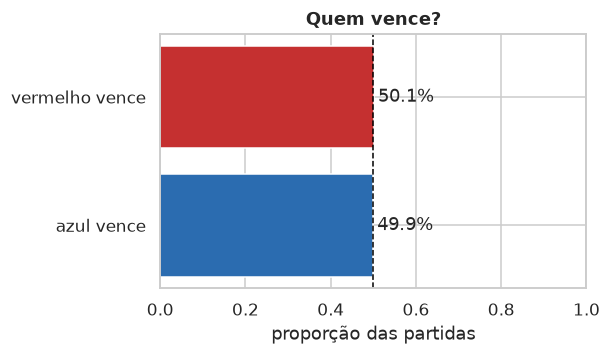

In [5]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.barh(target_share.index, target_share.values, color=[TEAM_PALETTE["blue"], TEAM_PALETTE["red"]])
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.set(xlim=(0, 1), xlabel="proporção das partidas", title="Quem vence?")
for i, value in enumerate(target_share.values):
    ax.text(value + 0.01, i, f"{value:.1%}", va="center")
save_figure(fig, "eda_target_balance")
plt.show()

**Azul vence 49,9% · vermelho 50,1%.** Classes praticamente balanceadas → **sem necessidade de reamostragem nem de pesos de classe**;
acurácia é uma métrica legível (o baseline "chutar sempre azul" acerta ~50%).
Se 50,1% é estatisticamente diferente de 50% é pergunta do Notebook 02 (teste binomial).

## 3. Resumo estatístico — azul × vermelho lado a lado

Se o jogo é simétrico, as distribuições dos dois lados devem ser quase idênticas.

In [6]:
side_stats = [
    "wards_placed",
    "wards_destroyed",
    "kills",
    "assists",
    "dragons",
    "heralds",
    "towers_destroyed",
    "total_gold",
    "total_experience",
    "avg_level",
    "total_minions_killed",
    "total_jungle_minions_killed",
]
side_by_side = pd.concat(
    {
        side: df[[f"{side}_{s}" for s in side_stats]]
        .set_axis(side_stats, axis=1)
        .describe()
        .T[["mean", "50%", "std", "min", "max"]]
        for side in ("blue", "red")
    },
    axis=1,
)
side_by_side

blue                                  \
                                  mean        50%       std        min   
wards_placed                    22.288     16.000    18.019      5.000   
wards_destroyed                  2.825      3.000     2.175      0.000   
kills                            6.184      6.000     3.011      0.000   
assists                          6.645      6.000     4.065      0.000   
dragons                          0.362      0.000     0.481      0.000   
heralds                          0.188      0.000     0.391      0.000   
towers_destroyed                 0.051      0.000     0.244      0.000   
total_gold                  16,503.456 16,398.000 1,535.447 10,730.000   
total_experience            17,928.110 17,951.000 1,200.524 10,098.000   
avg_level                        6.916      7.000     0.305      4.600   
total_minions_killed           216.700    218.000    21.858     90.000   
total_jungle_minions_killed     50.510     50.000     9.898      0.000   

                                              red                       \
                                   max       mean        50%       std   
wards_placed                   250.000     22.368     16.000    18.457   
wards_destroyed                 27.000      2.723      2.000     2.138   
kills                           22.000      6.138      6.000     2.934   
assists                         29.000      6.662      6.000     4.061   
dragons                          1.000      0.413      0.000     0.492   
heralds                          1.000      0.160      0.000     0.367   
towers_destroyed                 4.000      0.043      0.000     0.217   
total_gold                  23,701.000 16,489.041 16,378.000 1,490.888   
total_experience            22,224.000 17,961.730 17,974.000 1,198.584   
avg_level                        8.000      6.925      7.000     0.305   
total_minions_killed           283.000    217.349    218.000    21.912   
total_jungle_minions_killed     92.000     51.313     51.000    10.028   

                                                   
                                   min        max  
wards_placed                     6.000    276.000  
wards_destroyed                  0.000     24.000  
kills                            0.000     22.000  
assists                          0.000     28.000  
dragons                          0.000      1.000  
heralds                          0.000      1.000  
towers_destroyed                 0.000      2.000  
total_gold                  11,212.000 22,732.000  
total_experience            10,465.000 22,269.000  
avg_level                        4.800      8.200  
total_minions_killed           107.000    289.000  
total_jungle_minions_killed      4.000     92.000

Médias e medianas dos dois lados são muito próximas — nenhum lado domina estruturalmente
os primeiros 10 min. Duas coisas chamam atenção: o **máximo de `wards_placed` (250–276)**
contra uma mediana de 16, e `towers_destroyed` quase sempre zero (torre aos 10 min é rara).

## 4. Redundâncias determinísticas

O contrato Pandera já garante essas igualdades; aqui elas ficam **visíveis** porque justificam
remover colunas na camada silver. Coluna que é função exata de outra só infla
multicolinearidade e não carrega informação nova.

In [7]:
redundancies = {
    "blue_kills == red_deaths": (df["blue_kills"], df["red_deaths"]),
    "red_kills == blue_deaths": (df["red_kills"], df["blue_deaths"]),
    "blue_gold_diff == blue_gold - red_gold": (
        df["blue_gold_diff"],
        df["blue_total_gold"] - df["red_total_gold"],
    ),
    "red_gold_diff == -blue_gold_diff": (df["red_gold_diff"], -df["blue_gold_diff"]),
    "blue_xp_diff == blue_xp - red_xp": (
        df["blue_experience_diff"],
        df["blue_total_experience"] - df["red_total_experience"],
    ),
    "red_xp_diff == -blue_xp_diff": (df["red_experience_diff"], -df["blue_experience_diff"]),
    "gold_per_min == total_gold / 10": (df["blue_gold_per_min"], df["blue_total_gold"] / 10),
    "cs_per_min == minions / 10": (df["blue_cs_per_min"], df["blue_total_minions_killed"] / 10),
    "elite_monsters == dragons + heralds": (
        df["blue_elite_monsters"],
        df["blue_dragons"] + df["blue_heralds"],
    ),
    "blue_first_blood == 1 - red_first_blood": (df["blue_first_blood"], 1 - df["red_first_blood"]),
}
pd.Series(
    {rule: equality_rate(a, b) for rule, (a, b) in redundancies.items()}, name="% linhas"
).to_frame()

,% linhas
blue_kills == red_deaths,1.000
red_kills == blue_deaths,1.000
blue_gold_diff == blue_gold - red_gold,1.000
red_gold_diff == -blue_gold_diff,1.000
blue_xp_diff == blue_xp - red_xp,1.000
red_xp_diff == -blue_xp_diff,1.000
gold_per_min == total_gold / 10,1.000
cs_per_min == minions / 10,1.000
elite_monsters == dragons + heralds,1.000
blue_first_blood == 1 - red_first_blood,1.000


Todas valem em **100%** das partidas → 13 colunas são removíveis sem perda de informação
(ver decisões ao final).

## 5. Distribuições por resultado

Trabalho a partir daqui com **diferenças azul − vermelho**: é a forma natural de descrever
vantagem ("+2k de gold"), e o jogo é simétrico.

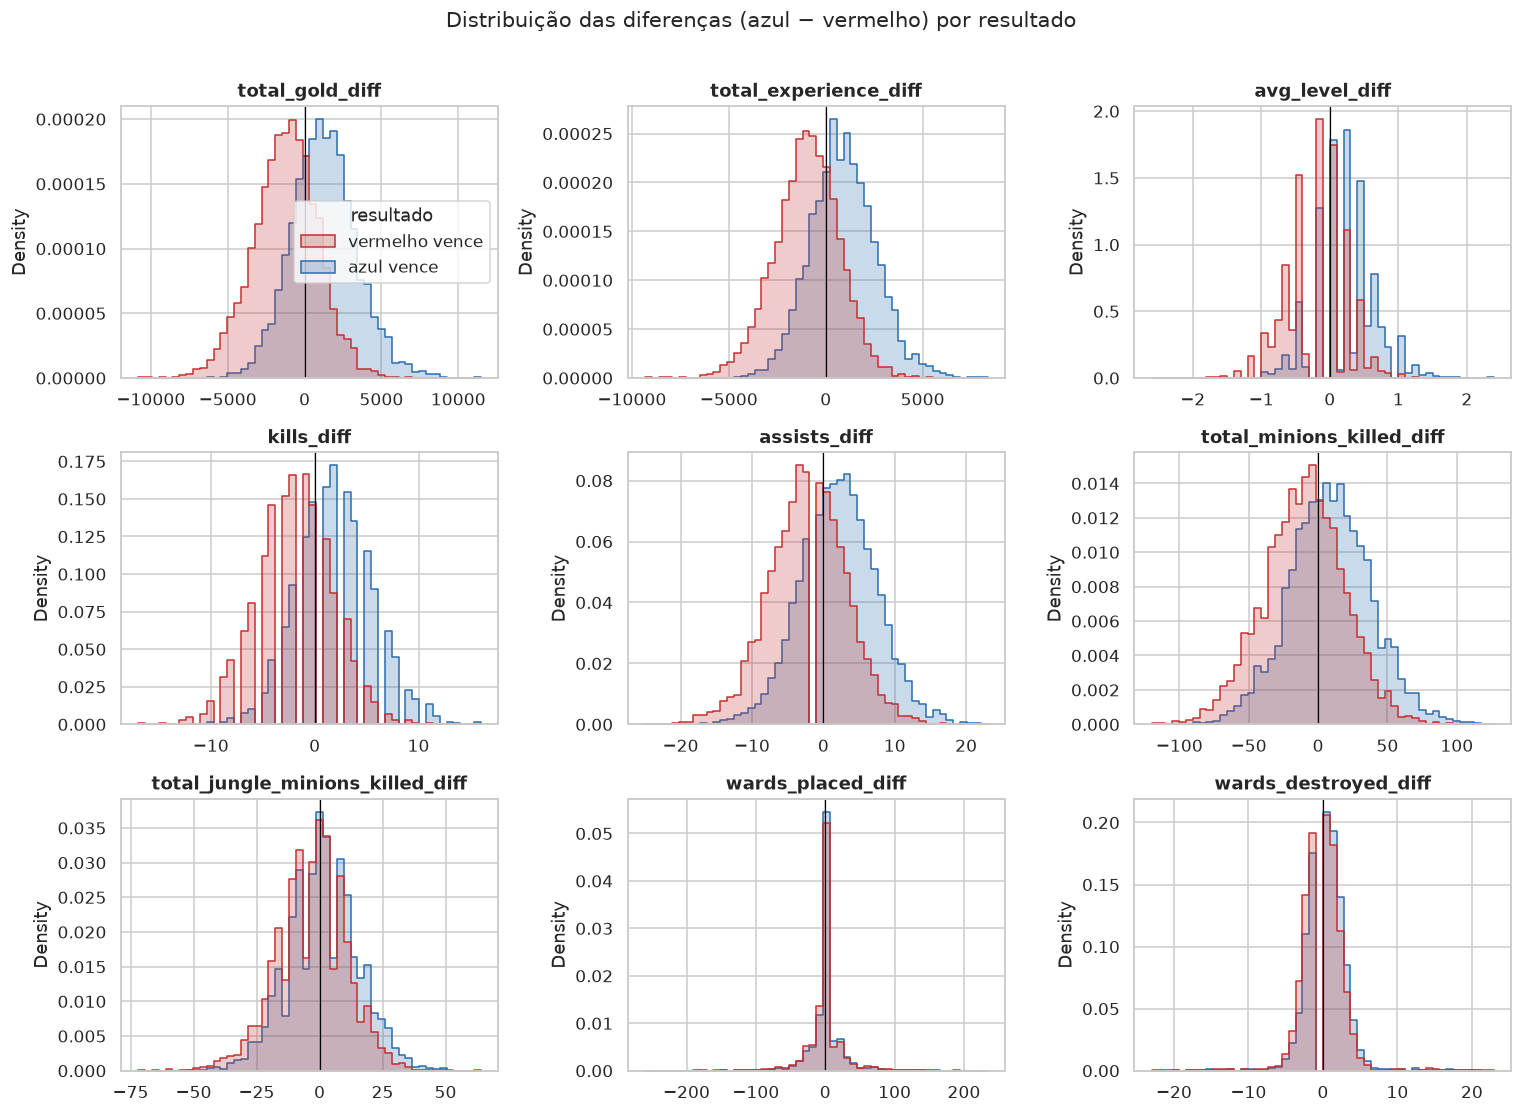

In [8]:
diffs = side_diffs(df).assign(blue_first_blood=df["blue_first_blood"], **{TARGET: df[TARGET]})
diff_cols = [c for c in diffs.columns if c != TARGET]
outcome_palette = {OUTCOME_LABELS[k]: color for k, color in OUTCOME_PALETTE.items()}
plot_df = diffs.assign(resultado=diffs[TARGET].map(OUTCOME_LABELS))
continuous = [
    "total_gold_diff",
    "total_experience_diff",
    "avg_level_diff",
    "kills_diff",
    "assists_diff",
    "total_minions_killed_diff",
    "total_jungle_minions_killed_diff",
    "wards_placed_diff",
    "wards_destroyed_diff",
]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, column in zip(axes.flat, continuous, strict=True):
    sns.histplot(
        data=plot_df,
        x=column,
        hue="resultado",
        palette=outcome_palette,
        bins=50,
        element="step",
        stat="density",
        common_norm=False,
        ax=ax,
    )
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(column)
    ax.set_xlabel("")
    if ax is not axes.flat[0]:
        ax.get_legend().remove()
fig.suptitle("Distribuição das diferenças (azul − vermelho) por resultado", y=1.01, fontsize=14)
fig.tight_layout()
save_figure(fig, "eda_diff_distributions_by_outcome")
plt.show()

Leitura de jogador:
- **Gold, XP, nível e kills** separam bem as classes — as curvas se deslocam em sentidos opostos.
- **CS** separa menos; **jungle CS** e **wards** quase se sobrepõem: sozinhos dizem pouco.
- As diffs são aproximadamente simétricas em torno de zero, como esperado num jogo espelhado.

## 6. Outliers de `wards_placed`

In [9]:
wards = pd.DataFrame(
    {side: outlier_summary(df[f"{side}_wards_placed"]) for side in ("blue", "red")}
).T
wards["n > 100"] = [(df[f"{side}_wards_placed"] > 100).sum() for side in ("blue", "red")]
wards

,p50,p90,p95,p99,p99.5,max,n > 100
blue,16.000,40.000,53.000,105.000,129.000,250.000,108
red,16.000,40.000,53.000,104.000,135.830,276.000,109


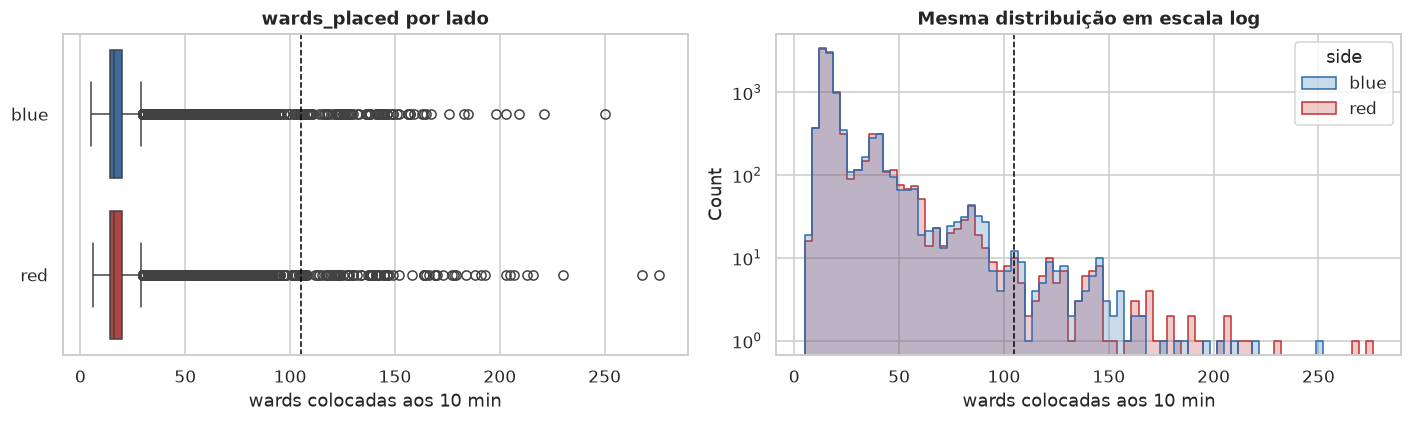

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
long_wards = df.melt(
    value_vars=["blue_wards_placed", "red_wards_placed"], var_name="side", value_name="wards"
).assign(side=lambda d: d["side"].str.split("_").str[0])
sns.boxplot(
    data=long_wards, x="wards", y="side", hue="side", palette=TEAM_PALETTE, ax=axes[0], legend=False
)
axes[0].set(title="wards_placed por lado", xlabel="wards colocadas aos 10 min", ylabel="")
sns.histplot(
    data=long_wards,
    x="wards",
    hue="side",
    palette=TEAM_PALETTE,
    bins=80,
    ax=axes[1],
    element="step",
)
axes[1].set(
    yscale="log", title="Mesma distribuição em escala log", xlabel="wards colocadas aos 10 min"
)
for ax in axes:
    ax.axvline(df["blue_wards_placed"].quantile(0.99), color="black", linestyle="--", linewidth=1)
fig.tight_layout()
save_figure(fig, "eda_wards_placed_outliers")
plt.show()

Os valores altos são **plausíveis no jogo?** Aos 10 min, um time com trinkets, ward de
suporte e control wards chega a algumas dezenas de wards. 250 wards em 10 min é ~1 ward a
cada 2,4 s — não é jogo normal. Pode ser artefato de coleta (ex.: contagem de totems
especiais / modos) ou comportamento atípico. Antes de decidir, a pergunta que importa:
**essas partidas se comportam diferente quanto ao resultado?**

In [11]:
high = pd.DataFrame(
    {
        "grupo": ["azul > 100 wards", "vermelho > 100 wards", "demais partidas"],
        "n": [
            (df["blue_wards_placed"] > 100).sum(),
            (df["red_wards_placed"] > 100).sum(),
            ((df["blue_wards_placed"] <= 100) & (df["red_wards_placed"] <= 100)).sum(),
        ],
        "taxa de vitória azul": [
            df.loc[df["blue_wards_placed"] > 100, TARGET].mean(),
            df.loc[df["red_wards_placed"] > 100, TARGET].mean(),
            df.loc[
                (df["blue_wards_placed"] <= 100) & (df["red_wards_placed"] <= 100), TARGET
            ].mean(),
        ],
    }
)
high

,grupo,n,taxa de vitória azul
0,azul > 100 wards,108,0.454
1,vermelho > 100 wards,109,0.495
2,demais partidas,9663,0.500


In [12]:
wards_bins = win_rate_by_bins(df, "blue_wards_placed", bins=[0, 10, 15, 20, 30, 40, 60, 100, 300])
wards_bins[["n", "win_rate", "ci_low", "ci_high"]]

,n,win_rate,ci_low,ci_high
blue_wards_placed,,,,
"(0, 10]",154,0.429,0.353,0.508
"(10, 15]",3571,0.472,0.455,0.488
"(15, 20]",3845,0.518,0.502,0.533
"(20, 30]",718,0.550,0.514,0.586
"(30, 40]",670,0.528,0.491,0.566
"(40, 60]",552,0.486,0.444,0.527
"(60, 100]",261,0.475,0.415,0.536
"(100, 300]",108,0.454,0.363,0.548


O que os dados mostram:
- A distribuição é **multimodal na cauda** (picos perto de 40, 85 e 145 na escala log) — padrão
  típico de artefato de coleta/contagem, não de um contínuo de "times que wardam muito".
- A relação com a vitória é **não-monotônica**: sobe até 20–30 wards (55%) e cai depois;
  o lado com >100 wards vence **45%** (IC 36–55%, n=108) — nenhuma vantagem.
- Nas demais 40 colunas essas partidas são normais (passaram em todo o contrato), então
  **não são linhas a apagar**: o problema está numa variável só, e ela é fraca.

**Decisão:** manter as linhas e aplicar **cap (winsorização) no p99 de `wards_placed`**,
com o percentil **ajustado só no treino, dentro do `Pipeline`** (evita vazamento do teste).
Por quê: protege a regressão logística de pontos de alavancagem extrema; para árvores o cap
é praticamente neutro. A Etapa 5 compara com e sem cap via CV.

## 7. Correlação entre as diferenças

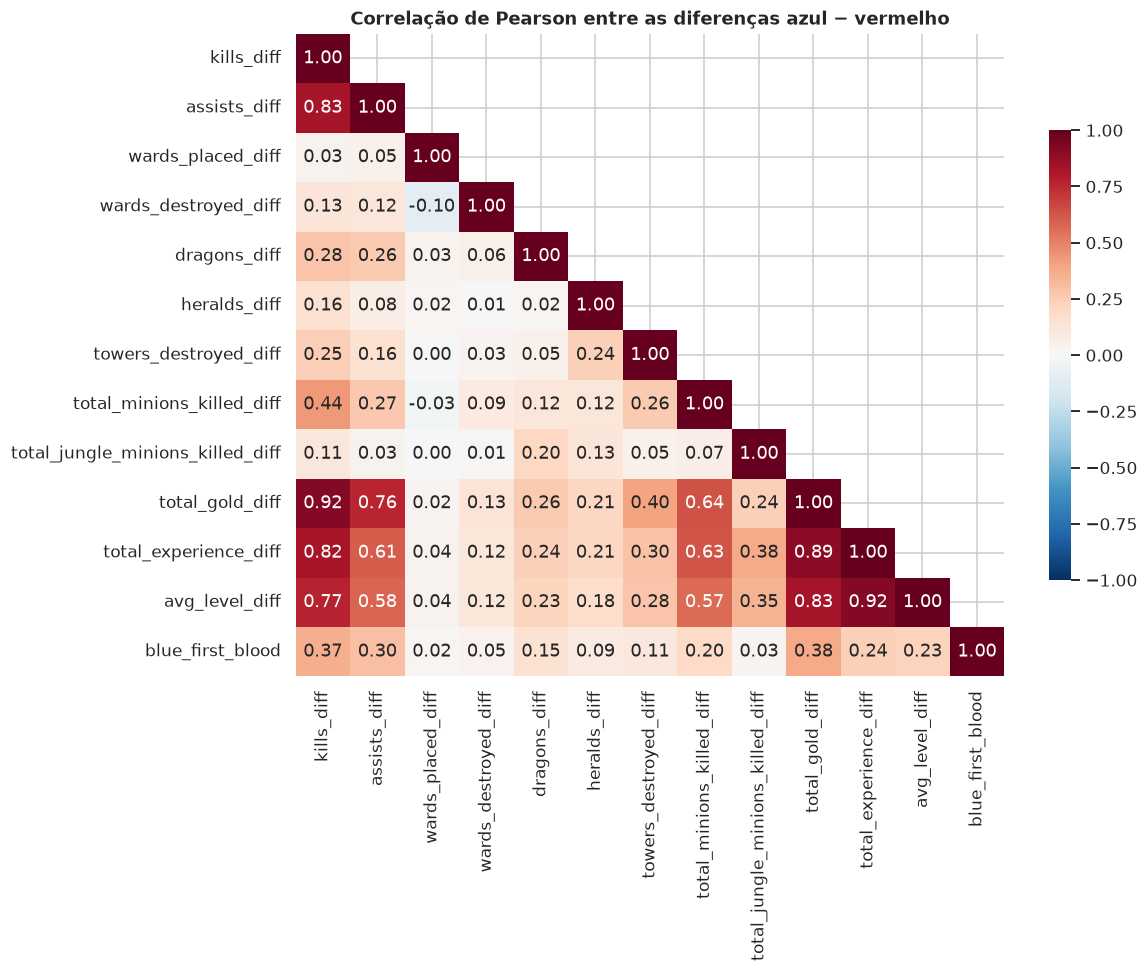

In [13]:
corr = diffs[diff_cols].corr()
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
    cbar_kws={"shrink": 0.7},
)
ax.set_title("Correlação de Pearson entre as diferenças azul − vermelho")
fig.tight_layout()
save_figure(fig, "eda_diff_correlation_heatmap")
plt.show()

Um **bloco de "vantagem econômica"** fortemente correlacionado: `gold ↔ kills` (0,92),
`gold ↔ xp` (0,89), `xp ↔ avg_level` (0,92). Faz sentido no jogo: kill dá gold e XP, XP vira
nível. Visão (`wards_*`) é praticamente ortogonal a tudo.

## 8. Multicolinearidade (VIF) — absolutos vs. diffs

Comparo dois conjuntos candidatos, já **sem as redundâncias determinísticas** (que dariam VIF
infinito):
- **absolutos:** estatísticas de cada time em colunas separadas (24 colunas);
- **diffs:** azul − vermelho (12 colunas) + `blue_first_blood`.

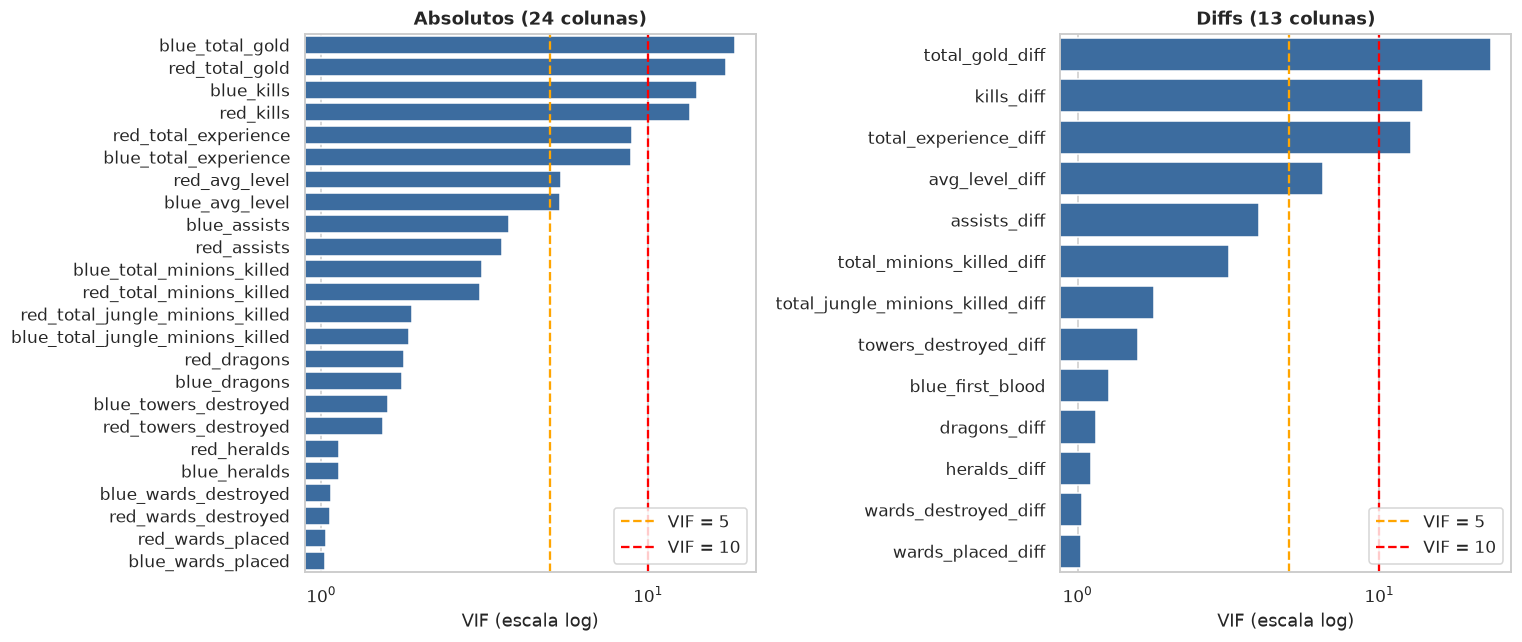

In [14]:
absolute_cols = [f"{side}_{s}" for side in ("blue", "red") for s in side_stats]
vif_abs = compute_vif(df[absolute_cols])
vif_diff = compute_vif(diffs[diff_cols])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (title, vif) in zip(
    axes, [("Absolutos (24 colunas)", vif_abs), ("Diffs (13 colunas)", vif_diff)], strict=True
):
    sns.barplot(data=vif, y="feature", x="vif", color=TEAM_PALETTE["blue"], ax=ax)
    ax.axvline(5, color="orange", linestyle="--", label="VIF = 5")
    ax.axvline(10, color="red", linestyle="--", label="VIF = 10")
    ax.set(xscale="log", title=title, ylabel="", xlabel="VIF (escala log)")
    ax.legend()
fig.tight_layout()
save_figure(fig, "eda_vif_absolutes_vs_diffs")
plt.show()

In [15]:
pd.concat(
    {"absolutos": vif_abs.head(8).reset_index(drop=True), "diffs": vif_diff.reset_index(drop=True)},
    axis=1,
)

absolutos                                    diffs       
                  feature    vif                           feature    vif
0         blue_total_gold 18.478                   total_gold_diff 23.398
1          red_total_gold 17.356                        kills_diff 13.983
2              blue_kills 14.117             total_experience_diff 12.756
3               red_kills 13.452                    avg_level_diff  6.513
4    red_total_experience  8.942                      assists_diff  3.996
5   blue_total_experience  8.868         total_minions_killed_diff  3.168
6           red_avg_level  5.409  total_jungle_minions_killed_diff  1.798
7          blue_avg_level  5.377             towers_destroyed_diff  1.588
8                     NaN    NaN                  blue_first_blood  1.267
9                     NaN    NaN                      dragons_diff  1.153
10                    NaN    NaN                      heralds_diff  1.104
11                    NaN    NaN              wards_destroyed_diff  1.036
12                    NaN    NaN                 wards_placed_diff  1.024

**Minha hipótese estava errada:** esperava que trocar absolutos por diffs reduzisse a
multicolinearidade. Não reduz — `total_gold_diff` tem VIF **23** (vs. 18 de `blue_total_gold`).
A colinearidade está no **bloco econômico** (gold, kills, xp, level), qualquer que seja a
representação: no jogo, kill *é* gold e XP.

O que isso implica:
- **Previsão:** VIF alto não prejudica a acurácia; regressão logística regularizada e árvores
  lidam bem. Diffs continuam preferíveis por outros motivos: metade das colunas, simetria
  azul/vermelho por construção e leitura direta ("+2k de gold").
- **Inferência (Notebook 02):** coeficientes de um logit com gold + kills + xp juntos seriam
  instáveis. Por isso os testes de hipótese usam **`gold_diff` como controle único**.
- Visão, objetivos e first blood têm VIF ≈ 1 — informação ortogonal ao gold.

## 9. Relação de cada variável com a vitória

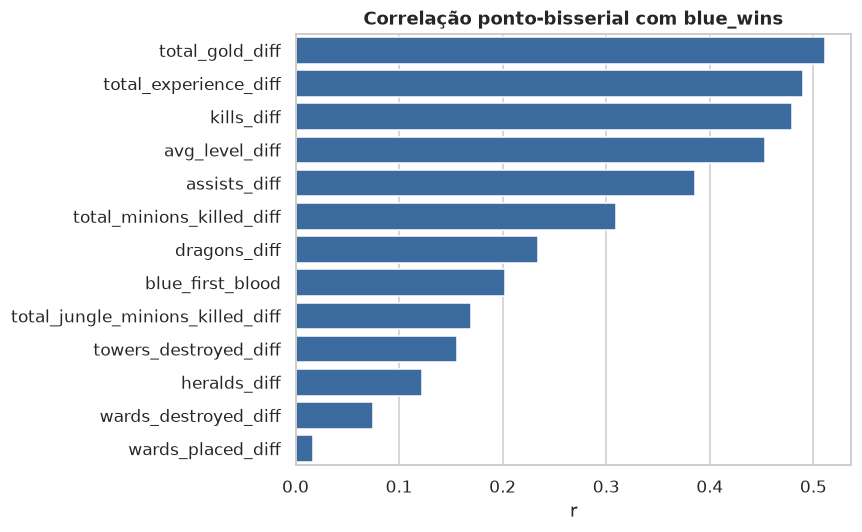

,feature,r,p_value
0,total_gold_diff,0.511,0.000
1,total_experience_diff,0.490,0.000
2,kills_diff,0.479,0.000
3,avg_level_diff,0.453,0.000
4,assists_diff,0.386,0.000
5,total_minions_killed_diff,0.309,0.000
6,dragons_diff,0.234,0.000
7,blue_first_blood,0.202,0.000
8,total_jungle_minions_killed_diff,0.169,0.000
9,towers_destroyed_diff,0.156,0.000


In [16]:
target_corr = target_correlations(diffs, diff_cols)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=target_corr, y="feature", x="r", color=TEAM_PALETTE["blue"], ax=ax)
ax.set(title="Correlação ponto-bisserial com blue_wins", xlabel="r", ylabel="")
fig.tight_layout()
save_figure(fig, "eda_target_correlation")
plt.show()
target_corr

### 9.1 A curva de win-probability "bruta" do gold

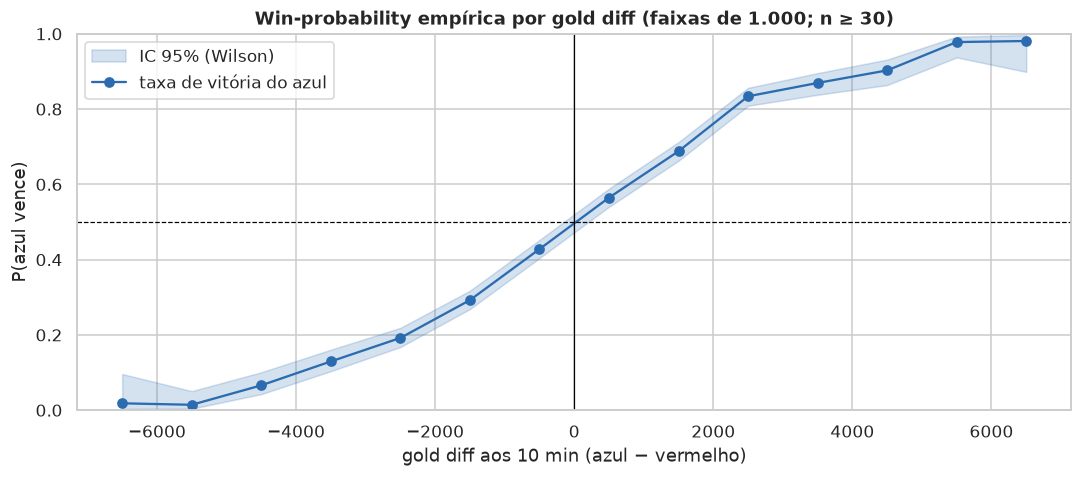

In [17]:
gold_curve = win_rate_by_bins(df, "blue_gold_diff", bins=range(-12000, 12001, 1000))
gold_curve = gold_curve[gold_curve["n"] >= 30]

fig, ax = plt.subplots(figsize=(10, 4.5))
centers = gold_curve["center"].astype(float)
ax.fill_between(
    centers,
    gold_curve["ci_low"],
    gold_curve["ci_high"],
    color=TEAM_PALETTE["blue"],
    alpha=0.2,
    label="IC 95% (Wilson)",
)
ax.plot(
    centers,
    gold_curve["win_rate"],
    marker="o",
    color=TEAM_PALETTE["blue"],
    label="taxa de vitória do azul",
)
ax.axhline(0.5, color="black", linestyle="--", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    xlabel="gold diff aos 10 min (azul − vermelho)",
    ylabel="P(azul vence)",
    ylim=(0, 1),
    title="Win-probability empírica por gold diff (faixas de 1.000; n ≥ 30)",
)
ax.legend()
fig.tight_layout()
save_figure(fig, "eda_win_rate_by_gold_diff")
plt.show()

In [18]:
gold_rule_accuracy = ((df["blue_gold_diff"] > 0).astype(int) == df[TARGET]).mean()
print(f"Regra 'quem tem mais gold vence': acurácia = {gold_rule_accuracy:.1%}")
gold_curve[["n", "win_rate", "ci_low", "ci_high"]]

Regra 'quem tem mais gold vence': acurácia = 72.3%


,n,win_rate,ci_low,ci_high
blue_gold_diff,,,,
"(-7000, -6000]",55,0.018,0.003,0.096
"(-6000, -5000]",140,0.014,0.004,0.051
"(-5000, -4000]",288,0.066,0.043,0.101
"(-4000, -3000]",533,0.129,0.104,0.161
"(-3000, -2000]",917,0.192,0.168,0.219
"(-2000, -1000]",1334,0.292,0.269,0.317
"(-1000, 0]",1629,0.428,0.404,0.452
"(0, 1000]",1619,0.565,0.540,0.589
"(1000, 2000]",1349,0.688,0.663,0.712


A curva tem forma de **sigmoide** quase perfeita, centrada em 0 → a regressão logística é
uma escolha natural, e explica por que só `gold_diff` já dá AUC ≈ 0,80.
- +1k de gold: 57% · +2k: 69% · +3k: 83% · +5k: 98%.
- A regra "quem tem mais gold vence" acerta **72,3%** — é o baseline a bater na Etapa 5.
- Gold diff explica a maior parte; o que resta para as outras variáveis é **pouco** e
  mora perto de zero (jogos parelhos), onde a incerteza real do jogo é maior.

### 9.2 Objetivos e first blood

In [19]:
objectives = [
    "blue_first_blood",
    "blue_dragons",
    "red_dragons",
    "blue_heralds",
    "red_heralds",
    "blue_towers_destroyed",
    "red_towers_destroyed",
]
objective_rates = pd.concat(
    {col: win_rate_by_group(df, col) for col in objectives}, names=["variável", "valor"]
)
objective_rates[["n", "win_rate", "ci_low", "ci_high"]]

n  win_rate  ci_low  ci_high
variável              valor                                 
blue_first_blood      0      4892     0.397   0.384    0.411
                      1      4987     0.599   0.585    0.612
blue_dragons          0      6303     0.419   0.406    0.431
                      1      3576     0.641   0.625    0.657
red_dragons           0      5798     0.587   0.574    0.600
                      1      4081     0.374   0.359    0.389
blue_heralds          0      8022     0.477   0.466    0.488
                      1      1857     0.595   0.573    0.617
red_heralds           0      8298     0.520   0.509    0.531
                      1      1581     0.388   0.364    0.412
blue_towers_destroyed 0      9415     0.486   0.476    0.497
                      1       429     0.737   0.693    0.776
                      2        27     0.963   0.817    0.993
                      3         7     1.000   0.646    1.000
                      4         1     1.000   0.207    1.000
red_towers_destroyed  0      9483     0.510   0.500    0.520
                      1       367     0.237   0.196    0.283
                      2        29     0.241   0.122    0.421

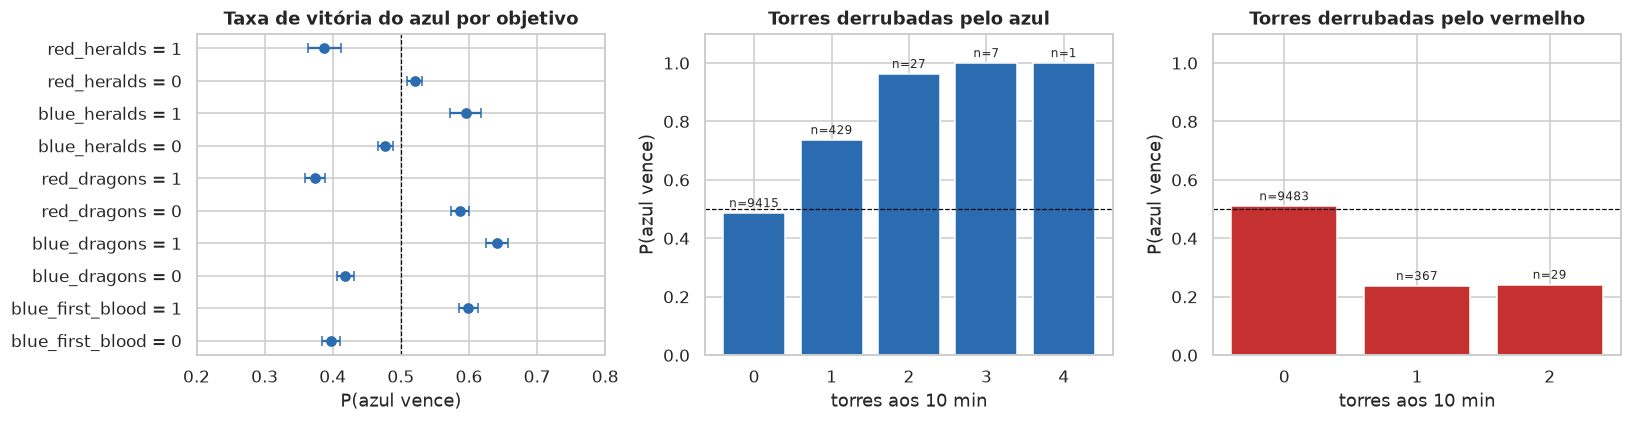

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
binary = objective_rates.loc[
    ["blue_first_blood", "blue_dragons", "red_dragons", "blue_heralds", "red_heralds"]
].reset_index()
binary["label"] = binary["variável"] + " = " + binary["valor"].astype(str)
axes[0].errorbar(
    binary["win_rate"],
    binary["label"],
    xerr=[binary["win_rate"] - binary["ci_low"], binary["ci_high"] - binary["win_rate"]],
    fmt="o",
    color=TEAM_PALETTE["blue"],
    capsize=3,
)
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=0.8)
axes[0].set(xlim=(0.2, 0.8), title="Taxa de vitória do azul por objetivo", xlabel="P(azul vence)")
for ax, side, side_pt in zip(axes[1:], ("blue", "red"), ("azul", "vermelho"), strict=True):
    towers = win_rate_by_group(df, f"{side}_towers_destroyed")
    ax.bar(towers.index.astype(str), towers["win_rate"], color=TEAM_PALETTE[side])
    for x, (rate, n) in enumerate(zip(towers["win_rate"], towers["n"], strict=True)):
        ax.text(x, rate + 0.02, f"n={n}", ha="center", fontsize=8)
    ax.axhline(0.5, color="black", linestyle="--", linewidth=0.8)
    ax.set(
        ylim=(0, 1.1),
        title=f"Torres derrubadas pelo {side_pt}",
        xlabel="torres aos 10 min",
        ylabel="P(azul vence)",
    )
fig.tight_layout()
save_figure(fig, "eda_win_rate_by_objectives")
plt.show()

- **Dragão** (64% vs 42%) e **first blood** (60% vs 40%) movem bastante a taxa bruta;
  **arauto** um pouco menos (60% vs 48%).
- **Torre aos 10 min** é rara (4–5% das partidas) mas forte: 1 torre azul → 74%,
  2 torres → 96% (n=27). Contagens de 3+ são raríssimas.

Atenção: essas taxas são **brutas**. Quem pega o dragão geralmente já está na frente em gold;
separar "o dragão ajuda" de "quem está ganhando pega o dragão" é exatamente o trabalho do
Notebook 02 (logit controlando `gold_diff`).

## 10. Decisões tomadas (alimentam a Etapa 4)

| # | Decisão | Evidência |
|---|---|---|
| 1 | **Remover 13 colunas redundantes no silver:** `*_deaths`, `*_gold_per_min`, `*_cs_per_min`, `*_elite_monsters`, `red_first_blood`, `red_gold_diff`, `red_experience_diff`, e recalcular `blue_gold_diff`/`blue_experience_diff` a partir dos totais | §4: igualdades em 100% das linhas |
| 2 | **Conjunto principal = diffs azul − vermelho** (12 diffs + `blue_first_blood`). "Diffs + absolutos" fica como comparação na Etapa 5 | §5, §8: separação clara, metade das colunas, simetria |
| 3 | **`wards_placed`: manter linhas e aplicar cap no p99 (≈105), ajustado só no treino, dentro do `Pipeline`**; comparar com/sem cap na CV | §6: cauda multimodal (artefato provável), variável fraca, sem vantagem de resultado |
| 4 | **Notebook 02 usa `gold_diff` como controle único** nos logits de inferência | §8: bloco gold/kills/xp/level com VIF 6–23 |
| 5 | **Sem tratamento de colinearidade para previsão** (regularização na LR; árvores toleram). Remoção de `avg_level_diff`/`kills_diff` só se a CV mostrar ganho | §8 |
| 6 | **Sem balanceamento de classes**; acurácia é métrica legível | §2: 49,9% / 50,1% |
| 7 | **Baselines da Etapa 5:** Dummy (~50%) e "quem tem mais gold vence" (**72,3%** de acurácia) | §9.1 |
| 8 | **Manter `towers_destroyed` e `dragons`/`heralds` como diffs inteiros**; sem one-hot (pouca cardinalidade, relação monotônica) | §9.2 |

**Perguntas que passam para o Notebook 02:** a vantagem de lado (49,9%) é real? Quanto
dragão, arauto e torre valem **além** do gold que já geraram? First blood decide ou só
acompanha quem já está na frente? Visão importa quando se controla pelo gold?